# 01 - Analyse exploratoire des données (EDA)

**Projet** : classification binaire de la qualité du vin (`quality >= 7` → bon vin).
**Données** : vins rouges et blancs « Vinho Verde » (Cortez et al., 2009), fusionnés.

Plan :
1. Chargement et statistiques descriptives
2. Valeurs manquantes et doublons
3. Variable cible et équilibre des classes
4. Distributions et valeurs aberrantes
5. Corrélations et multicolinéarité (VIF)
6. Lien variables / cible
7. Effet du type de vin (rouge / blanc)
8. Conclusions et décisions de prétraitement

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src.config import FEATURES, FIGURES_DIR, RANDOM_STATE
from src.data import add_binary_target, load_wine_data

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Chargement et statistiques descriptives

In [2]:
df = add_binary_target(load_wine_data())
print("Dimensions :", df.shape)
df.head()

Dimensions : (6497, 14)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type,good
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0


In [3]:
df.dtypes.to_frame("dtype").T

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type,good
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,str,int64


In [4]:
desc = df[FEATURES + ["quality"]].describe().T
desc["skew"] = df[FEATURES + ["quality"]].skew()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900,1.723
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580,1.495
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660,0.472
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800,1.435
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611,5.400
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000,1.220
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000,-0.001
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039,0.504
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010,0.387
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000,1.797


Les 11 variables sont toutes numériques continues, sur des échelles très différentes
(ex. `total sulfur dioxide` jusqu'à ~440 contre `chlorides` < 0,7). Un **centrage-réduction** sera donc
indispensable pour les modèles à distance (k-NN, SVM) et la régression logistique régularisée.

## 2. Valeurs manquantes et doublons

In [5]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else "aucune")

dup_mask = df.duplicated(subset=FEATURES + ["quality", "type"], keep="first")
print(f"\nLignes dupliquées : {dup_mask.sum()} ({dup_mask.mean():.1%})")
print(df.assign(dup=dup_mask).groupby("type")["dup"].agg(["sum", "mean"]).round(3))

Valeurs manquantes par colonne :
aucune

Lignes dupliquées : 1177 (18.1%)
       sum   mean
type             
red    240  0.150
white  937  0.191


In [6]:
# Mêmes mesures mais qualité différente ? (conflit d'étiquette)
conflicts = (
    df.groupby(FEATURES + ["type"])["quality"].nunique().gt(1).sum()
)
print("Combinaisons de features identiques avec qualités différentes :", conflicts)

Combinaisons de features identiques avec qualités différentes : 0


**Décision** : aucune valeur manquante. En revanche ~18 % des lignes sont des doublons exacts. Les conserver
entraînerait une **fuite de données** (même vin dans le train et le test) et gonflerait artificiellement les scores.
On les supprimera avant le découpage train/test (`drop_duplicates`).

In [7]:
df_clean = df.drop_duplicates(subset=FEATURES + ["quality", "type"]).reset_index(drop=True)
print(f"Avant : {len(df)} lignes, après : {len(df_clean)} lignes")
print(df_clean["good"].value_counts(normalize=True).round(3).to_dict())

Avant : 6497 lignes, après : 5320 lignes
{0: 0.81, 1: 0.19}


## 3. Variable cible et équilibre des classes

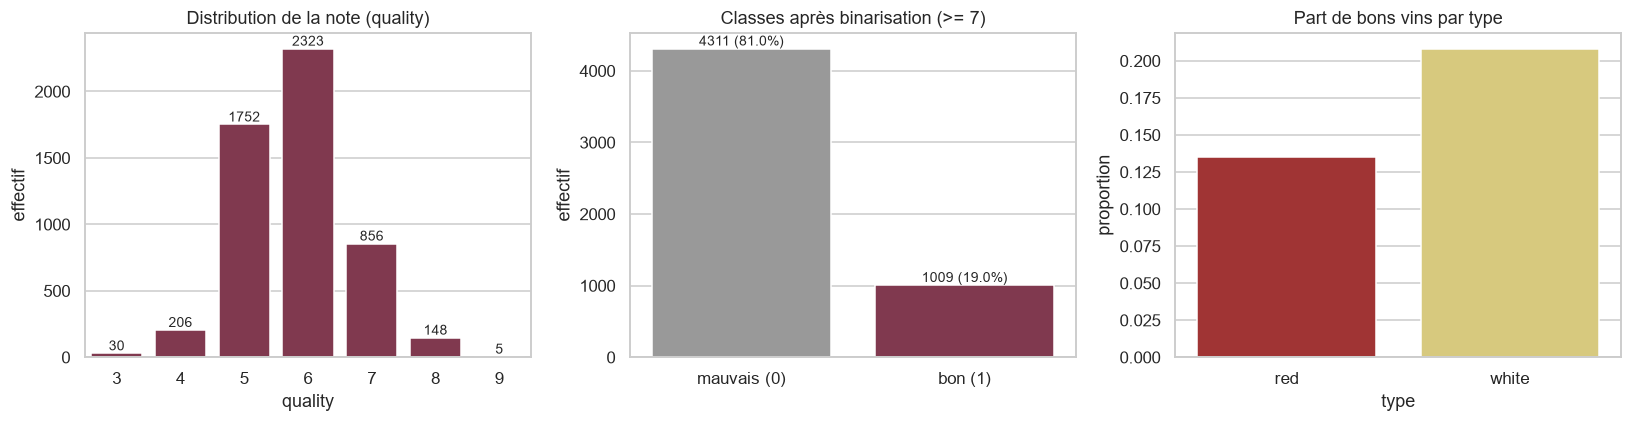

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

q = df_clean["quality"].value_counts().sort_index()
sns.barplot(x=q.index, y=q.values, ax=axes[0], color="#8c2d4b")
axes[0].set(title="Distribution de la note (quality)", xlabel="quality", ylabel="effectif")
for i, v in enumerate(q.values):
    axes[0].text(i, v, v, ha="center", va="bottom", fontsize=9)

g = df_clean["good"].value_counts().sort_index()
sns.barplot(x=["mauvais (0)", "bon (1)"], y=g.values, ax=axes[1], palette=["#999999", "#8c2d4b"], hue=["a", "b"], legend=False)
axes[1].set(title="Classes après binarisation (>= 7)", ylabel="effectif")
for i, v in enumerate(g.values):
    axes[1].text(i, v, f"{v} ({v / g.sum():.1%})", ha="center", va="bottom", fontsize=9)

rate = df_clean.groupby("type")["good"].mean()
sns.barplot(x=rate.index, y=rate.values, ax=axes[2], palette=["#b22222", "#e6d36f"], hue=rate.index, legend=False)
axes[2].set(title="Part de bons vins par type", ylabel="proportion")
plt.tight_layout()
save(fig, "01_target_distribution")
plt.show()

- Classes **déséquilibrées** (~80 / 20) : l'accuracy seule serait trompeuse (un classifieur « toujours mauvais » obtient ~80 %).
  On privilégiera **F1, rappel de la classe 1, ROC-AUC et PR-AUC**, un découpage **stratifié** et un traitement du déséquilibre
  (`class_weight='balanced'`, éventuellement SMOTE **dans** le pipeline de validation croisée).
- Les notes extrêmes (3 et 9) sont très rares : une approche multiclasse serait peu fiable, la binarisation est justifiée.
- La proportion de bons vins diffère entre rouge et blanc : `type` est une information utile.

## 4. Distributions et valeurs aberrantes

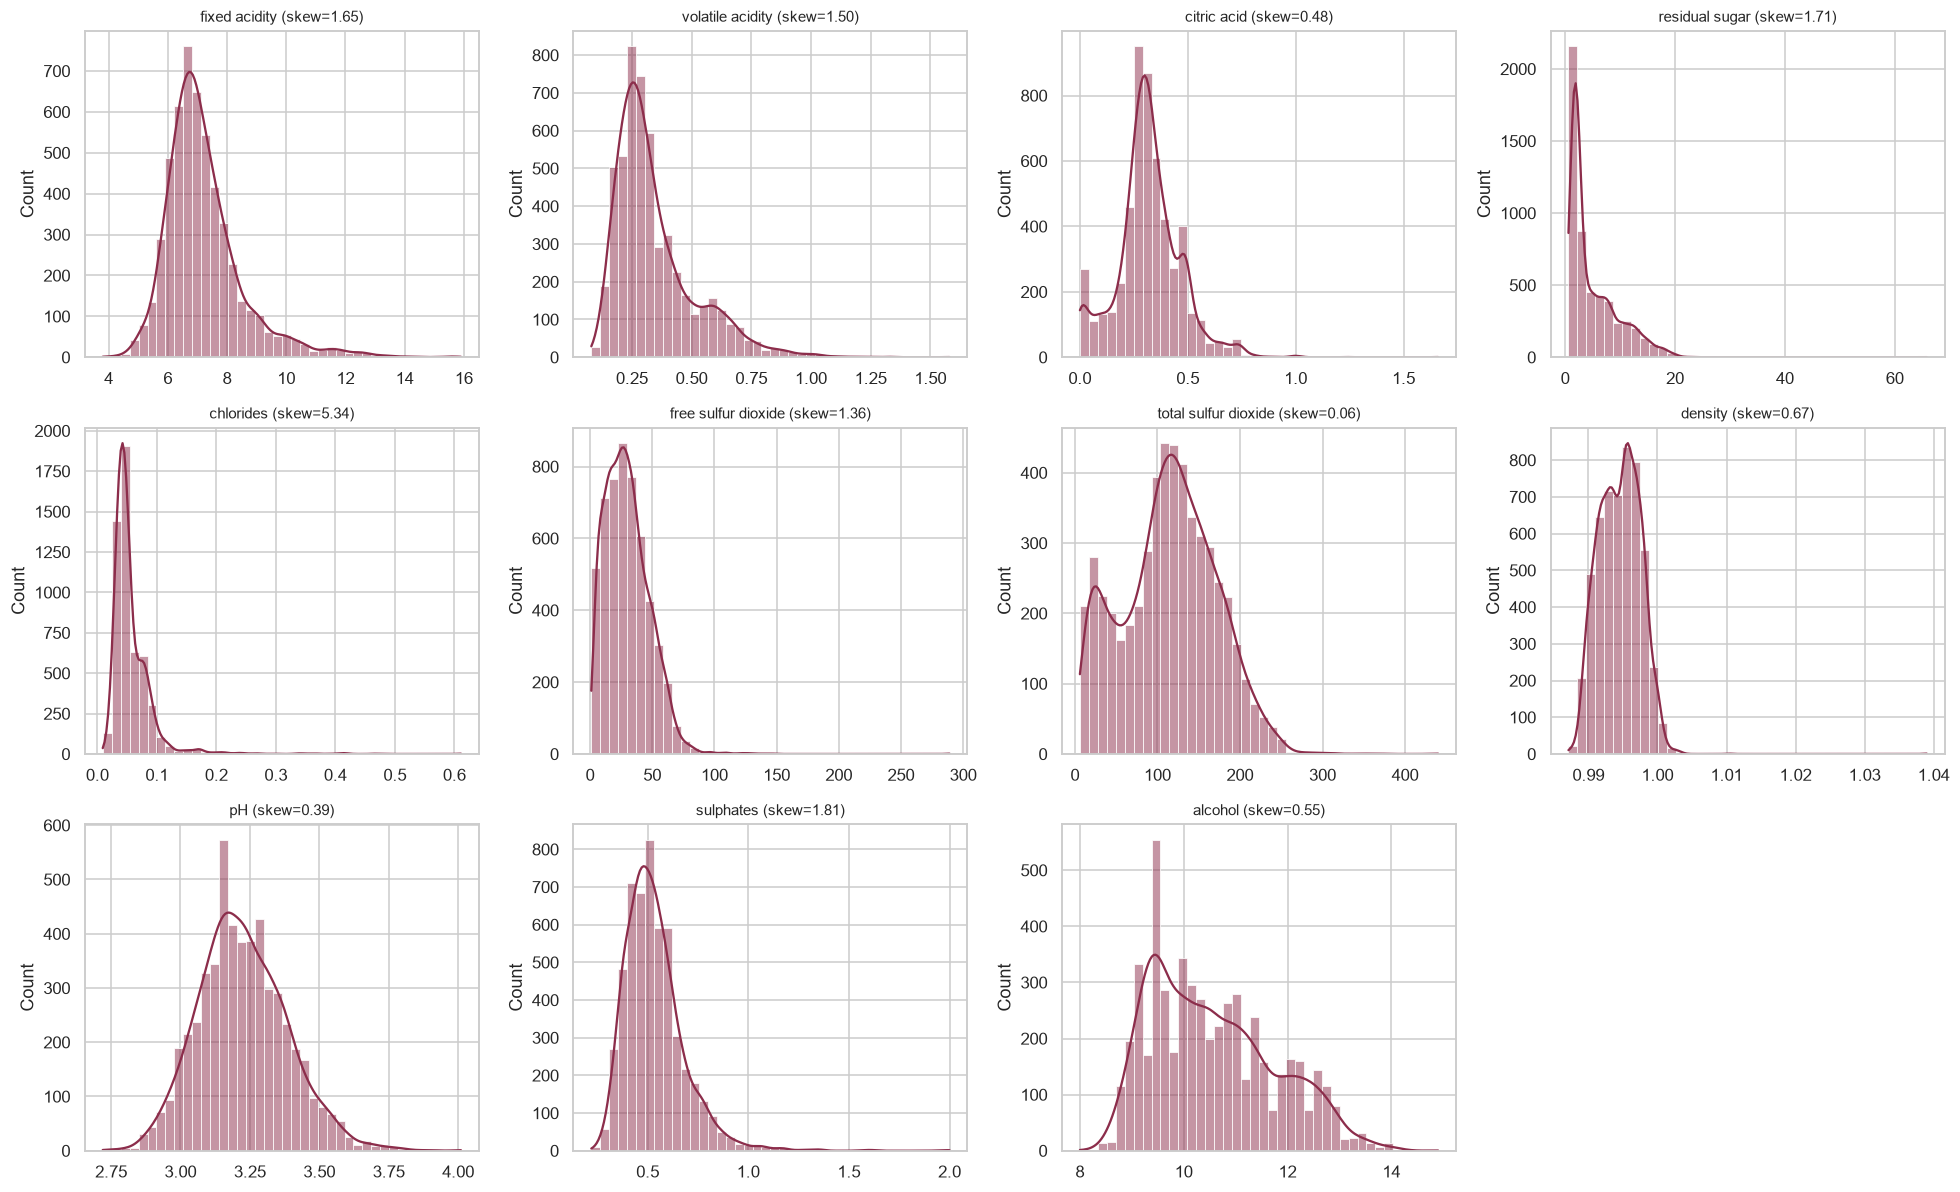

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df_clean[col], kde=True, ax=ax, color="#8c2d4b", bins=40)
    ax.set_title(f"{col} (skew={df_clean[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
save(fig, "02_histograms")
plt.show()

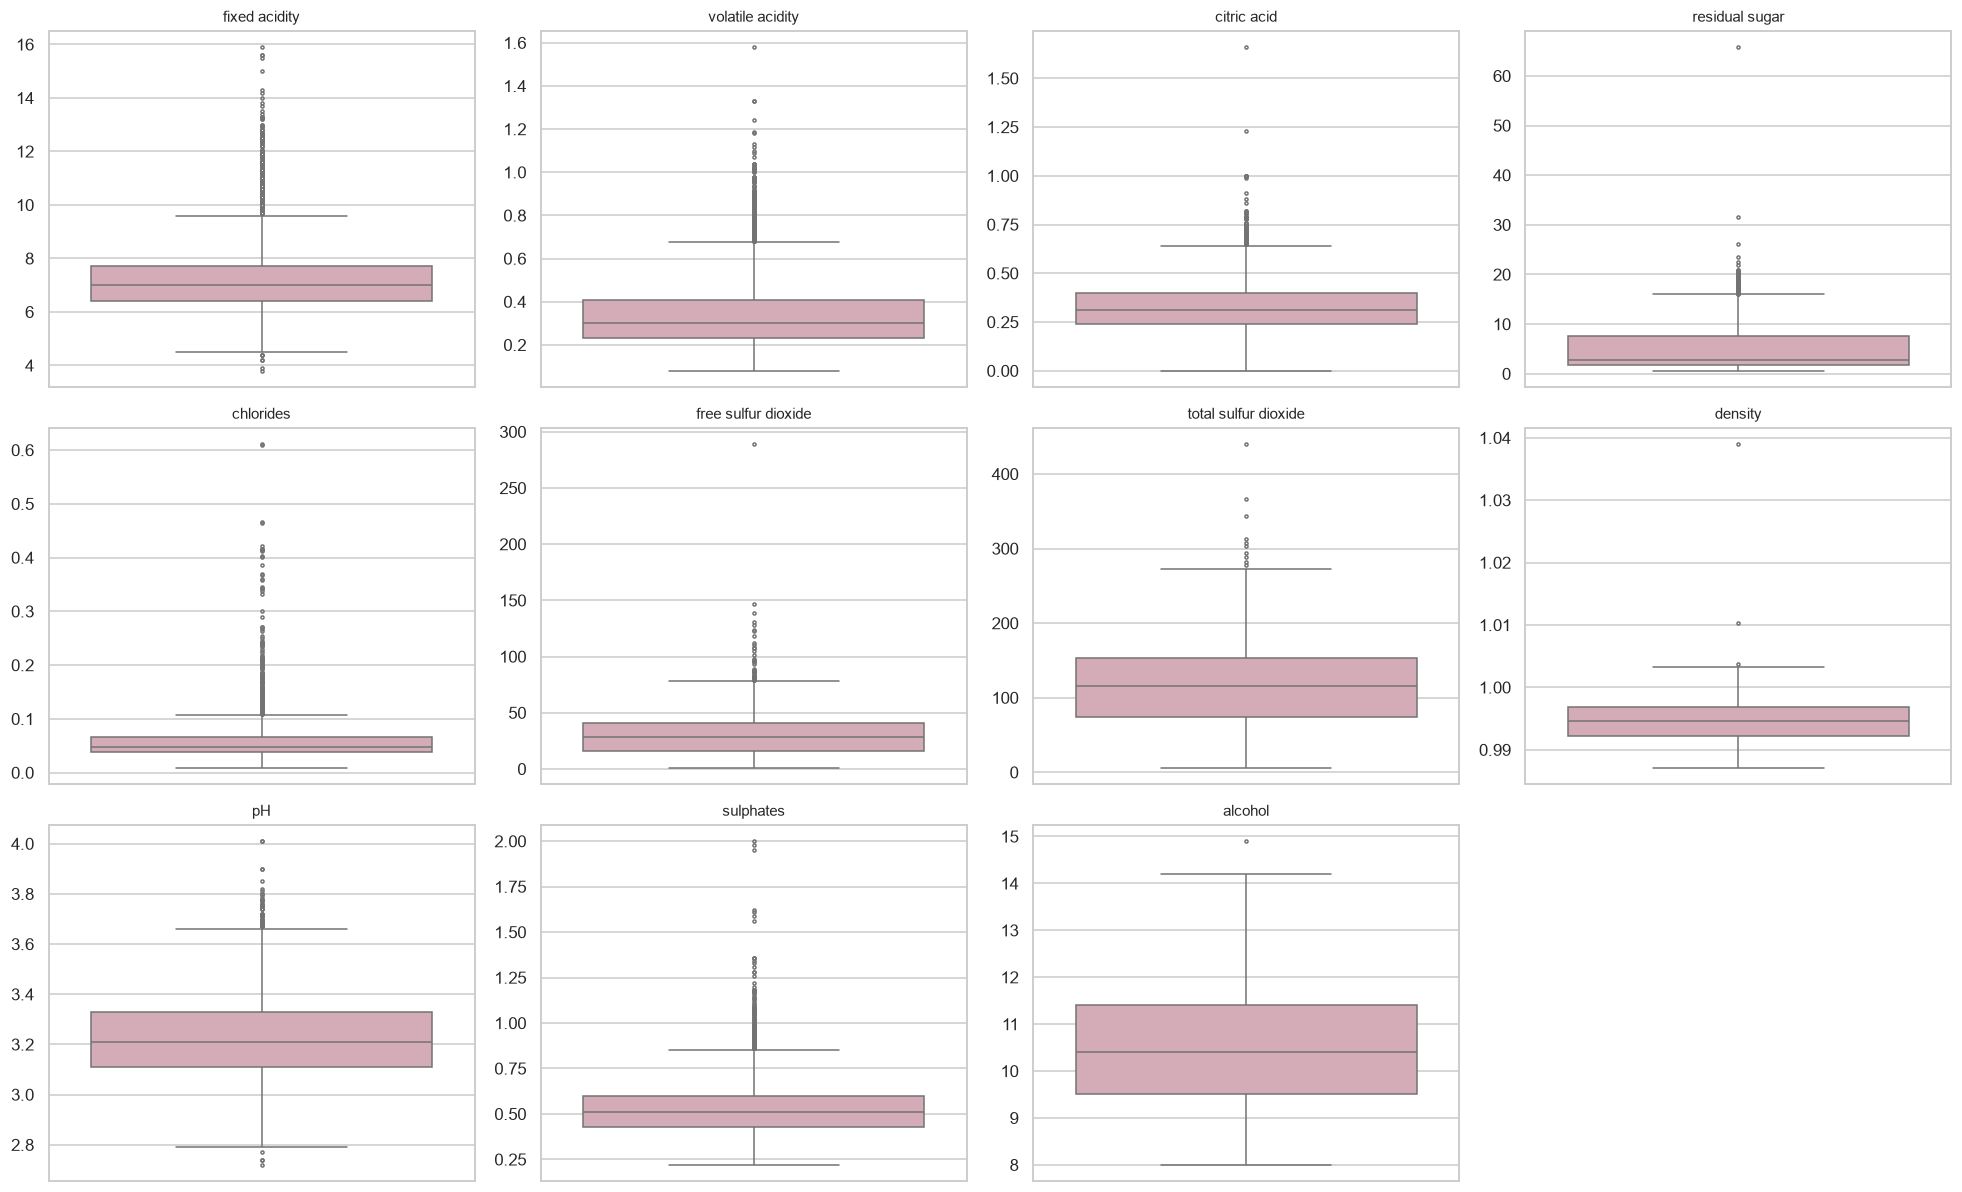

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=df_clean[col], ax=ax, color="#d9a5b5", fliersize=2)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
save(fig, "03_boxplots")
plt.show()

In [11]:
# Détection des aberrations : règle de Tukey (1.5 x IQR) et |z| > 3
q1, q3 = df_clean[FEATURES].quantile(0.25), df_clean[FEATURES].quantile(0.75)
iqr = q3 - q1
iqr_out = ((df_clean[FEATURES] < q1 - 1.5 * iqr) | (df_clean[FEATURES] > q3 + 1.5 * iqr))
z = (df_clean[FEATURES] - df_clean[FEATURES].mean()) / df_clean[FEATURES].std()
z_out = z.abs() > 3

outliers = pd.DataFrame({
    "n_IQR": iqr_out.sum(),
    "%_IQR": (iqr_out.mean() * 100).round(2),
    "n_|z|>3": z_out.sum(),
    "skew": df_clean[FEATURES].skew().round(2),
}).sort_values("n_IQR", ascending=False)
display(outliers)
print(f"Lignes avec au moins une aberration (IQR) : {iqr_out.any(axis=1).mean():.1%}")
print(f"Lignes avec au moins une aberration (|z|>3) : {z_out.any(axis=1).mean():.1%}")

,n_IQR,%_IQR,n_|z|>3,skew
fixed acidity,304,5.71,108,1.65
volatile acidity,279,5.24,77,1.50
chlorides,237,4.45,94,5.34
sulphates,163,3.06,63,1.81
citric acid,143,2.69,26,0.48
residual sugar,141,2.65,42,1.71
pH,49,0.92,32,0.39
free sulfur dioxide,44,0.83,27,1.36
total sulfur dioxide,10,0.19,8,0.06
density,3,0.06,3,0.67


Lignes avec au moins une aberration (IQR) : 20.6%
Lignes avec au moins une aberration (|z|>3) : 8.1%


In [12]:
# Les aberrations sont-elles associées à la classe « bon vin » ?
tmp = df_clean.assign(has_outlier=iqr_out.any(axis=1))
print(tmp.groupby("has_outlier")["good"].agg(["mean", "count"]).round(3))
print("\nValeurs extrêmes les plus parlantes :")
print(df_clean[FEATURES].agg(["min", "max"]).T[["min", "max"]])

              mean  count
has_outlier              
False        0.207   4226
True         0.123   1094

Valeurs extrêmes les plus parlantes :
                          min        max
fixed acidity         3.80000   15.90000
volatile acidity      0.08000    1.58000
citric acid           0.00000    1.66000
residual sugar        0.60000   65.80000
chlorides             0.00900    0.61100
free sulfur dioxide   1.00000  289.00000
total sulfur dioxide  6.00000  440.00000
density               0.98711    1.03898
pH                    2.72000    4.01000
sulphates             0.22000    2.00000
alcohol               8.00000   14.90000


**Lecture** :
- Plusieurs variables sont **fortement asymétriques à droite** (`chlorides`, `residual sugar`, `sulphates`, `free sulfur dioxide`...).
- ≈ 21 % des lignes contiennent au moins une aberration selon Tukey (≈ 8 % selon |z| > 3). Il s'agit de **mesures physico-chimiques plausibles**
  (vins très sucrés, très salés...) et non d'erreurs de saisie : seuls 1-2 points (ex. `residual sugar` ~65, `free sulfur dioxide` ~289)
  sont franchement extrêmes mais restent possibles.
- Les lignes contenant une aberration comptent **moins de bons vins** (12 % contre 21 %) : les supprimer (≈ 21 % des données) appauvrirait
  encore la classe minoritaire.
- **Décision** : on **ne supprime pas** les aberrations. On les traite par la **robustesse** : standardisation + éventuellement
  transformation `log1p` des variables très asymétriques, et modèles naturellement peu sensibles (arbres, SVM à marge souple).
  On comparera avec/sans transformation dans la phase 2.

## 5. Corrélations et multicolinéarité

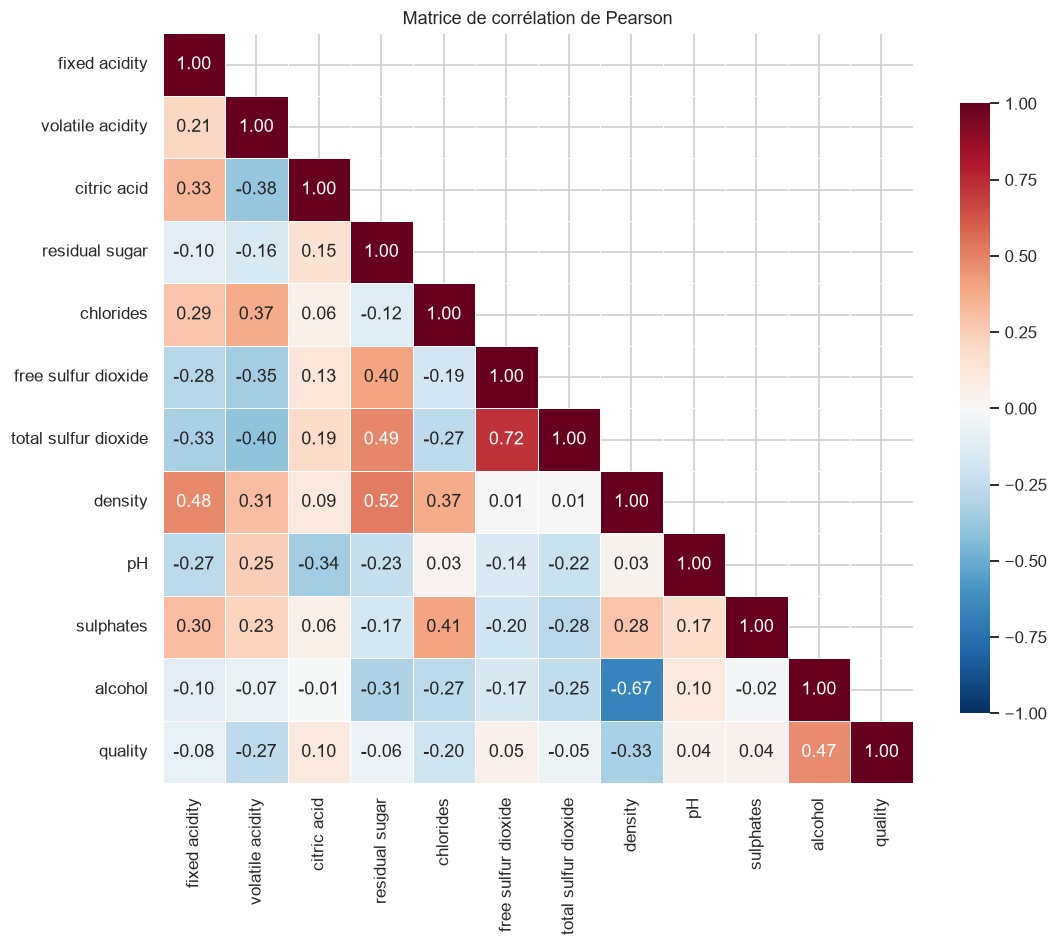

In [13]:
corr = df_clean[FEATURES + ["quality"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Matrice de corrélation de Pearson")
save(fig, "04_correlation_matrix")
plt.show()

In [14]:
pairs = (
    corr.where(~mask & ~np.eye(len(corr), dtype=bool))
    .stack()
    .rename("r")
    .reset_index()
    .rename(columns={"level_0": "var1", "level_1": "var2"})
)
pairs["|r|"] = pairs["r"].abs()
print("Paires fortement corrélées (|r| >= 0.5) :")
pairs[pairs["|r|"] >= 0.5].sort_values("|r|", ascending=False).drop(columns="|r|").round(3).reset_index(drop=True)

Paires fortement corrélées (|r| >= 0.5) :


,var1,var2,r
0,total sulfur dioxide,free sulfur dioxide,0.720
1,alcohol,density,-0.668
2,density,residual sugar,0.521


In [15]:
# VIF : un VIF > 5 (strict) ou > 10 (usuel) signale de la multicolinéarité
X = (df_clean[FEATURES] - df_clean[FEATURES].mean()) / df_clean[FEATURES].std()
X = X.assign(const=1.0)
vif = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(len(FEATURES))],
    index=FEATURES, name="VIF",
).sort_values(ascending=False)
vif.round(2).to_frame()

,VIF
density,14.92
residual sugar,6.43
fixed acidity,4.88
alcohol,4.58
total sulfur dioxide,2.93
pH,2.48
free sulfur dioxide,2.14
volatile acidity,1.96
citric acid,1.65
chlorides,1.63


**Lecture** :
- `density` est très corrélée à `alcohol` (négativement) et à `residual sugar` (positivement) : la densité est essentiellement
  déterminée par ces deux composantes.
- `free sulfur dioxide` et `total sulfur dioxide` sont corrélées (le premier est inclus dans le second).
- Le VIF de `density` (≈ 15) est très élevé, celui de `residual sugar` (≈ 6) est modéré : **multicolinéarité** qui déstabilise les coefficients de la régression logistique et justifie
  de la retirer ou de régulariser (L1/L2). Les arbres et SVM RBF y sont moins sensibles.
- Parmi les variables, `alcohol` est la plus corrélée à `quality`.

## 6. Lien entre les variables et la cible

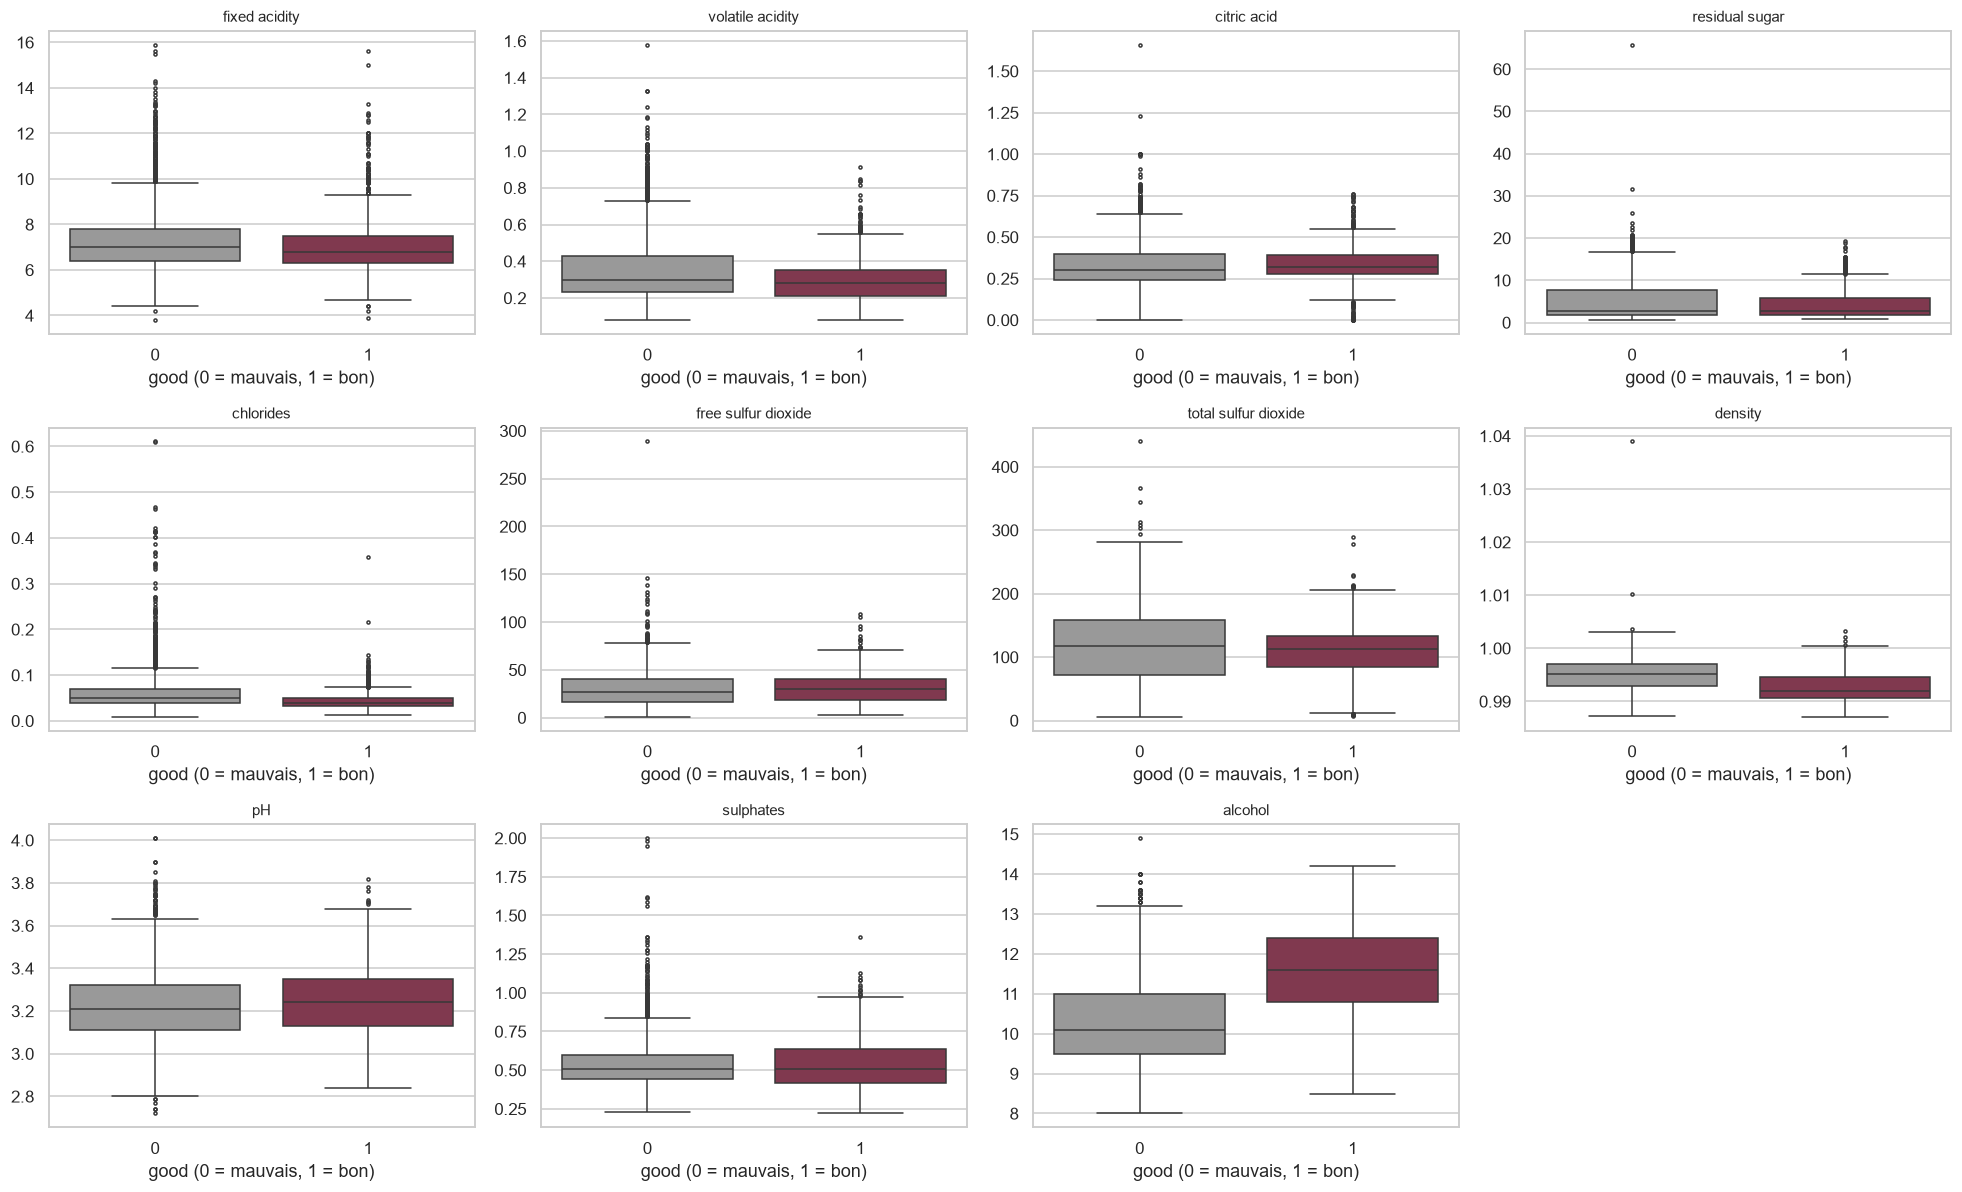

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df_clean, x="good", y=col, ax=ax, hue="good",
                palette=["#999999", "#8c2d4b"], fliersize=2, legend=False)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("good (0 = mauvais, 1 = bon)")
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
save(fig, "05_boxplots_by_class")
plt.show()

In [17]:
rows = []
for col in FEATURES:
    a = df_clean.loc[df_clean["good"] == 1, col]
    b = df_clean.loc[df_clean["good"] == 0, col]
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({
        "feature": col,
        "mean_bon": a.mean(),
        "mean_mauvais": b.mean(),
        "r_pointbiserial": stats.pointbiserialr(df_clean["good"], df_clean[col])[0],
        "p_mannwhitney": u.pvalue,
    })
mi = mutual_info_classif(df_clean[FEATURES], df_clean["good"], random_state=RANDOM_STATE)
univ = pd.DataFrame(rows).assign(mutual_info=mi).set_index("feature")
univ = univ.reindex(univ["mutual_info"].sort_values(ascending=False).index)
univ.round(4)

,mean_bon,mean_mauvais,r_pointbiserial,p_mannwhitney,mutual_info
feature,,,,,
alcohol,11.5732,10.3096,0.4177,0.0000,0.0937
density,0.9927,0.9950,-0.2950,0.0000,0.0656
chlorides,0.0444,0.0596,-0.1610,0.0000,0.0338
citric acid,0.3369,0.3142,0.0607,0.0000,0.0265
total sulfur dioxide,106.2111,115.9576,-0.0673,0.0000,0.0250
residual sugar,4.2591,5.2332,-0.0849,0.0012,0.0198
volatile acidity,0.2939,0.3559,-0.1444,0.0000,0.0124
sulphates,0.5447,0.5307,0.0368,0.1416,0.0025
free sulfur dioxide,30.4534,29.9391,0.0113,0.0164,0.0006


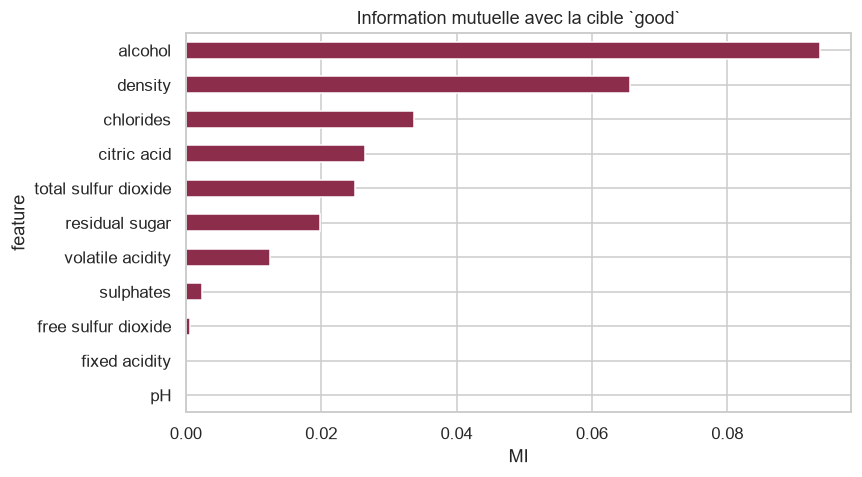

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
univ["mutual_info"].sort_values().plot.barh(ax=ax, color="#8c2d4b")
ax.set(title="Information mutuelle avec la cible `good`", xlabel="MI")
plt.tight_layout()
save(fig, "06_mutual_information")
plt.show()

**Lecture** : `alcohol` est de loin la variable la plus discriminante (r ≈ 0,42), suivie de `density` (r ≈ -0,30) et `chlorides`
(r ≈ -0,16) ; `volatile acidity` (r ≈ -0,14) ressort surtout par la corrélation linéaire. `sulphates`, `free sulfur dioxide`, `fixed acidity` et
`pH` apportent très peu d'information individuellement. Les bons vins ont en moyenne plus d'alcool, moins d'acidité volatile et moins de chlorures.
Ces résultats sont **univariés** et servent d'intuition ; la sélection formelle (L1, importance par arbres/forêt, élimination par VIF)
est faite en phase 2 **dans la validation croisée** pour éviter toute fuite.

## 7. Effet du type de vin (rouge / blanc)

type,red,white,ratio_white/red
fixed acidity,8.311,6.839,0.823
volatile acidity,0.529,0.281,0.530
citric acid,0.272,0.334,1.228
residual sugar,2.523,5.915,2.344
chlorides,0.088,0.046,0.521
free sulfur dioxide,15.893,34.889,2.195
total sulfur dioxide,46.826,137.194,2.930
density,0.997,0.994,0.997
pH,3.310,3.195,0.965
sulphates,0.659,0.490,0.744


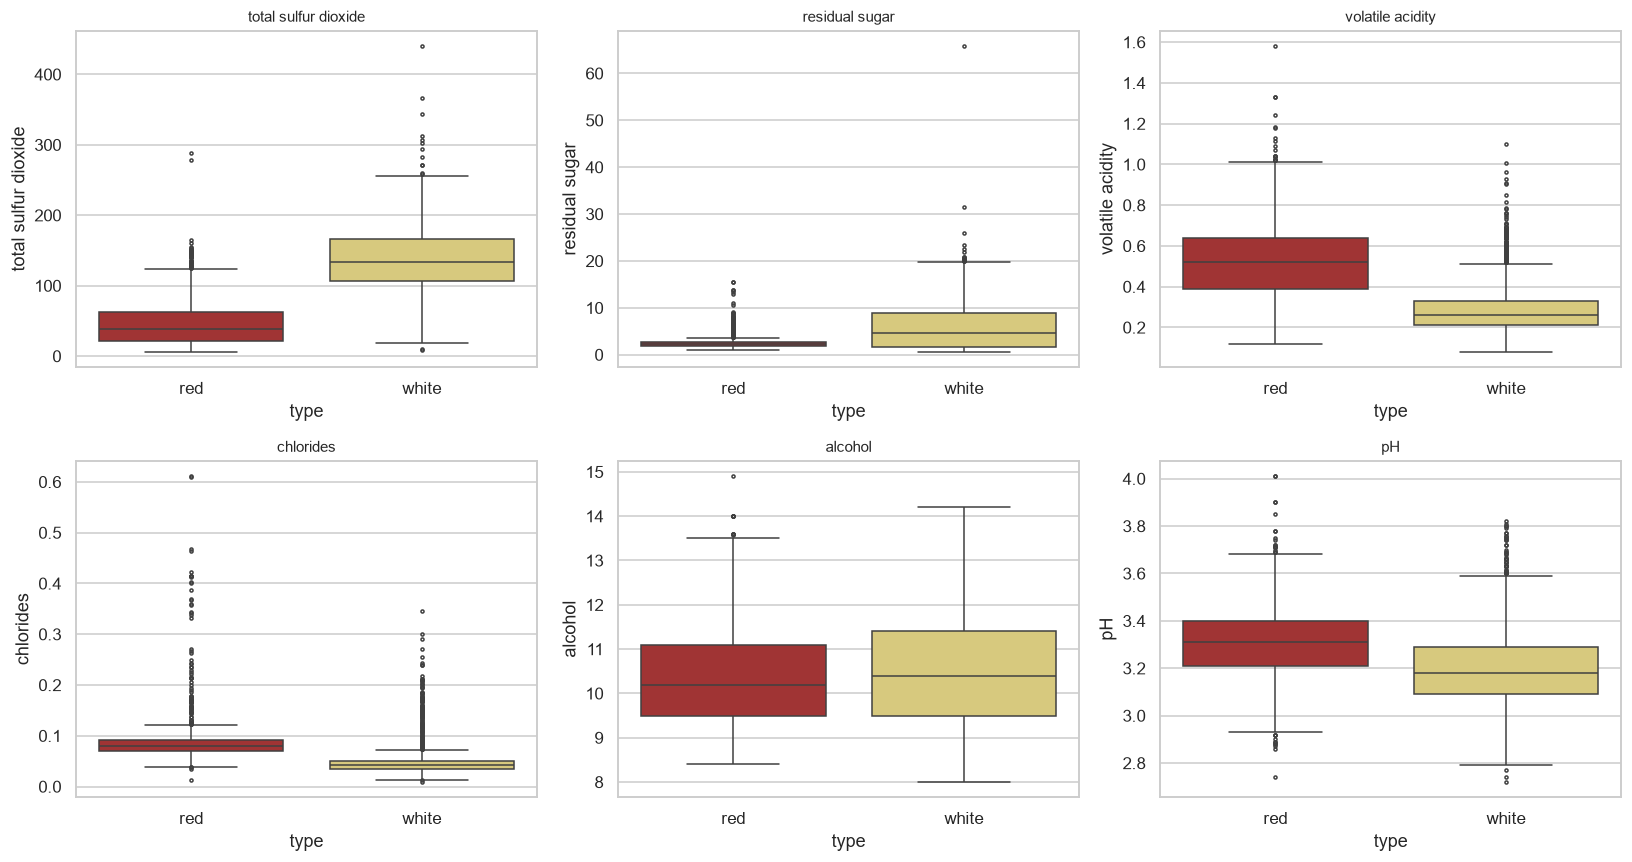

In [19]:
by_type = df_clean.groupby("type")[FEATURES].mean().T
by_type["ratio_white/red"] = by_type["white"] / by_type["red"]
display(by_type.round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["total sulfur dioxide", "residual sugar", "volatile acidity",
                                  "chlorides", "alcohol", "pH"]):
    sns.boxplot(data=df_clean, x="type", y=col, ax=ax, hue="type",
                palette=["#b22222", "#e6d36f"], fliersize=2, legend=False)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
save(fig, "07_features_by_type")
plt.show()

In [20]:
# La relation features -> cible est-elle la même dans les deux types ?
corr_by_type = pd.DataFrame({
    t: df_clean[df_clean["type"] == t][FEATURES + ["good"]].corr()["good"].drop("good")
    for t in ["red", "white"]
})
corr_by_type.round(3).sort_values("red", key=abs, ascending=False)

,red,white
alcohol,0.410,0.417
volatile acidity,-0.267,-0.057
citric acid,0.204,-0.023
sulphates,0.202,0.043
density,-0.158,-0.315
total sulfur dioxide,-0.136,-0.181
fixed acidity,0.116,-0.088
chlorides,-0.097,-0.190
free sulfur dioxide,-0.073,-0.023
pH,-0.054,0.117


Le type de vin modifie fortement la distribution de plusieurs variables (`total sulfur dioxide`, `residual sugar`, `volatile acidity`,
`chlorides`) et le taux de bons vins. La variable `type` sera **encodée (one-hot, 1 colonne binaire)** et ajoutée aux features.
La force de certaines relations varie entre rouge et blanc, ce qui plaide pour des modèles non linéaires capables de capter des interactions.

## 8. Conclusions et décisions de prétraitement

| Constat | Décision |
|---|---|
| 0 valeur manquante | Aucune imputation nécessaire |
| ~18 % de doublons exacts | Suppression avant le split (évite la fuite train/test) |
| Classes déséquilibrées (~80/20) | Split **stratifié**, métriques F1 / ROC-AUC / PR-AUC, `class_weight` ou SMOTE dans le pipeline |
| Échelles très hétérogènes | `StandardScaler` dans un `Pipeline` (fit sur le train uniquement) |
| Variables asymétriques + aberrations plausibles | Conservées ; comparaison avec `log1p`; modèles robustes |
| Multicolinéarité (`density`, SO2) | VIF, régularisation L1/L2, sélection de variables en phase 2 |
| `type` catégorielle | One-hot (`type_white`) |
| `alcohol` très discriminante | À confirmer par les méthodes de sélection multivariées |

**Prochaine étape (phase 2)** : `src/features.py` — transformateurs, pipeline de prétraitement et sélection de variables.